In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = sns.load_dataset("taxis")

In [6]:
print(df.isnull().sum())
for col in df.select_dtypes(include=['float64', 'int64']) .columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=['object', 'category']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


C:\Users\USER\AppData\Local\Temp\ipykernel_10704\1546904014.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object', 'category']).columns:


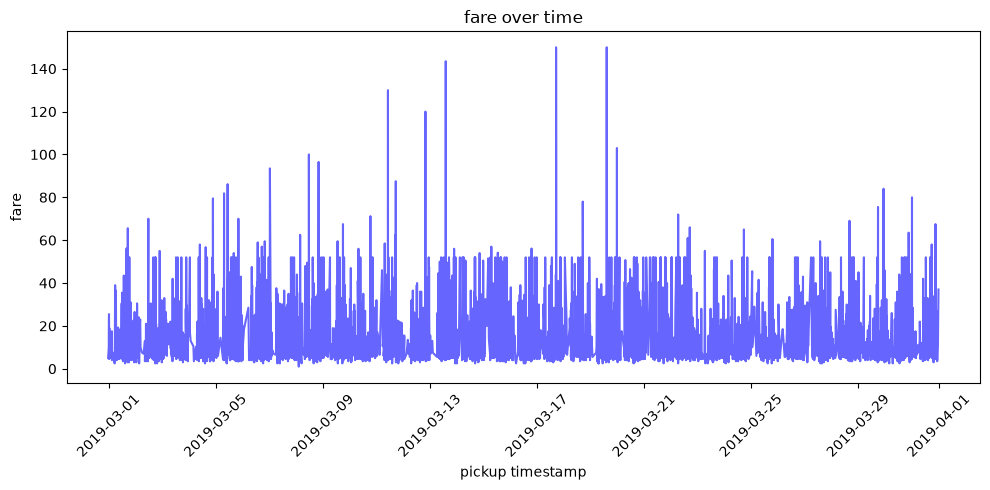

In [9]:
df['pickup'] = pd.to_datetime(df['pickup'])
df_sorted = df.sort_values('pickup')
plt.figure(figsize=(10,5))
plt.plot(df_sorted['pickup'], df_sorted['fare'], color='blue', alpha=0.6)
plt.xlabel('pickup timestamp')
plt.ylabel('fare')
plt.title('fare over time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

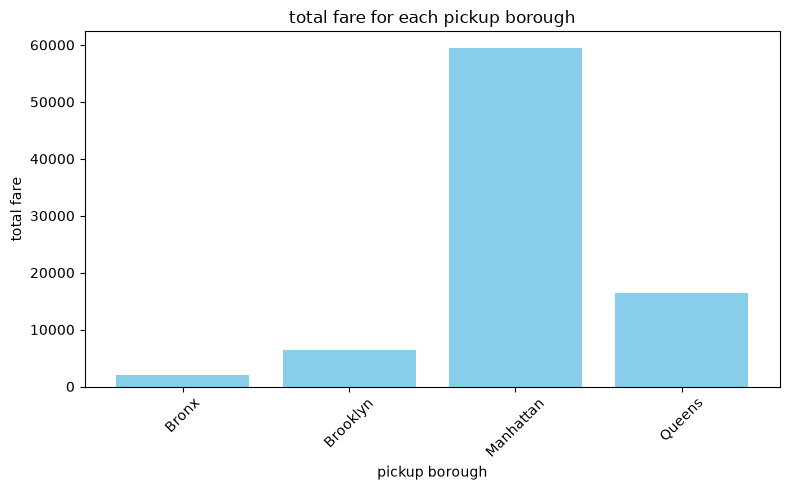

In [11]:
borough_fare = df.groupby('pickup_borough')['fare'].sum().reset_index()
plt.figure(figsize=(8,5))
plt.bar(borough_fare['pickup_borough'], borough_fare['fare'],color='skyblue')
plt.xlabel('pickup borough')
plt.ylabel('total fare')
plt.title('total fare for each pickup borough')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

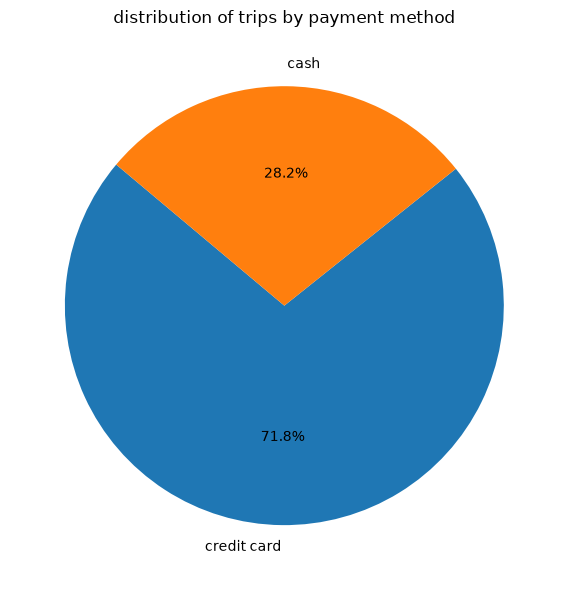

In [13]:
payment_counts = df['payment'].value_counts()
plt.figure(figsize=(6 ,6))
plt.pie(payment_counts, labels= payment_counts.index,autopct='%1.1f%%',startangle=140)
plt.title('distribution of trips by payment method')
plt.tight_layout()
plt.show()

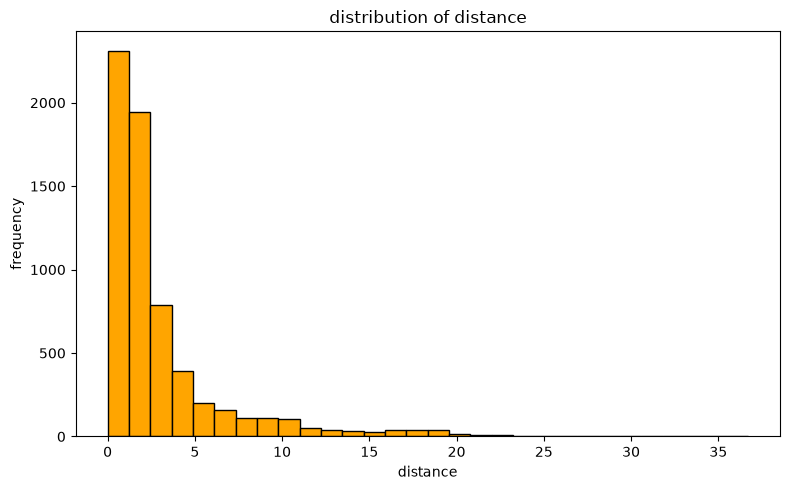

In [14]:
plt.figure(figsize=(8 ,5))
plt.hist(df['distance'], bins=30, color='orange', edgecolor='black' )
plt.xlabel('distance')
plt.ylabel('frequency')
plt.title('distribution of distance')
plt.tight_layout()
plt.show()

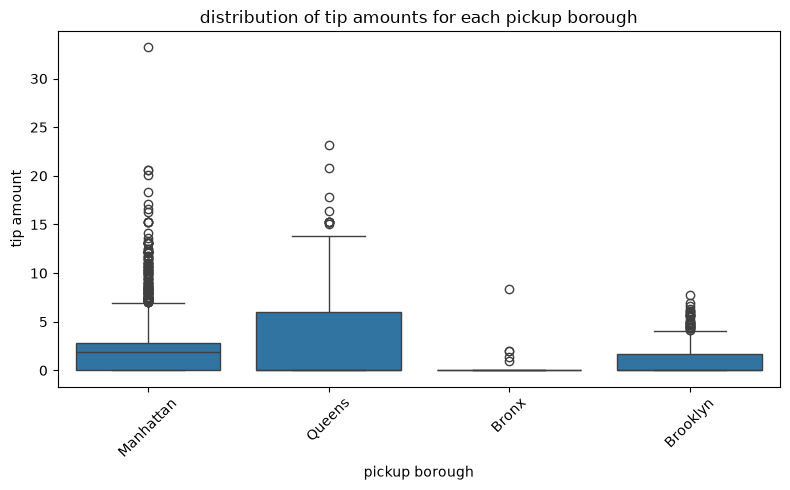

In [15]:
plt.figure(figsize=(8,5))
sns.boxplot(x='pickup_borough',y='tip',data=df)
plt.xlabel('pickup borough')
plt.ylabel('tip amount')
plt.title('distribution of tip amounts for each pickup borough')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

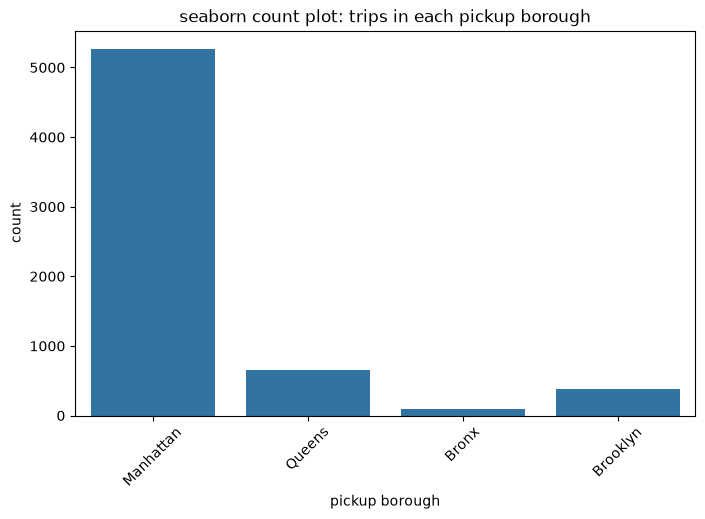

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
df= sns.load_dataset("taxis")
plt.figure(figsize=(8 ,5))
sns.countplot(data=df, x='pickup_borough')
plt.title('seaborn count plot: trips in each pickup borough')
plt.xlabel('pickup borough')
plt.ylabel('count')
plt.xticks(rotation=45)
plt.show()

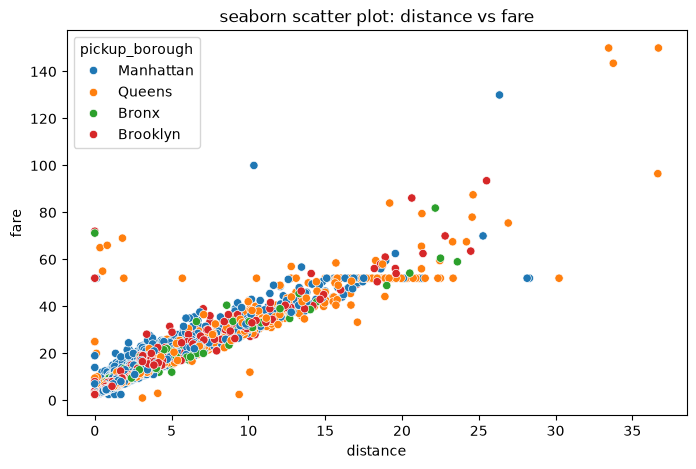

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='distance', y='fare', hue='pickup_borough')
plt.title('seaborn scatter plot: distance vs fare')
plt.xlabel('distance')
plt.ylabel('fare')
plt.show()

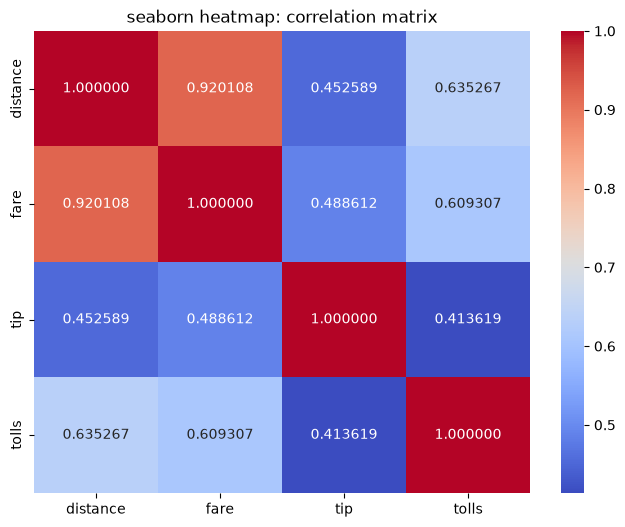

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8 ,6))
correlation=df[['distance','fare','tip','tolls']].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='2f')
plt.title('seaborn heatmap: correlation matrix')
plt.show()

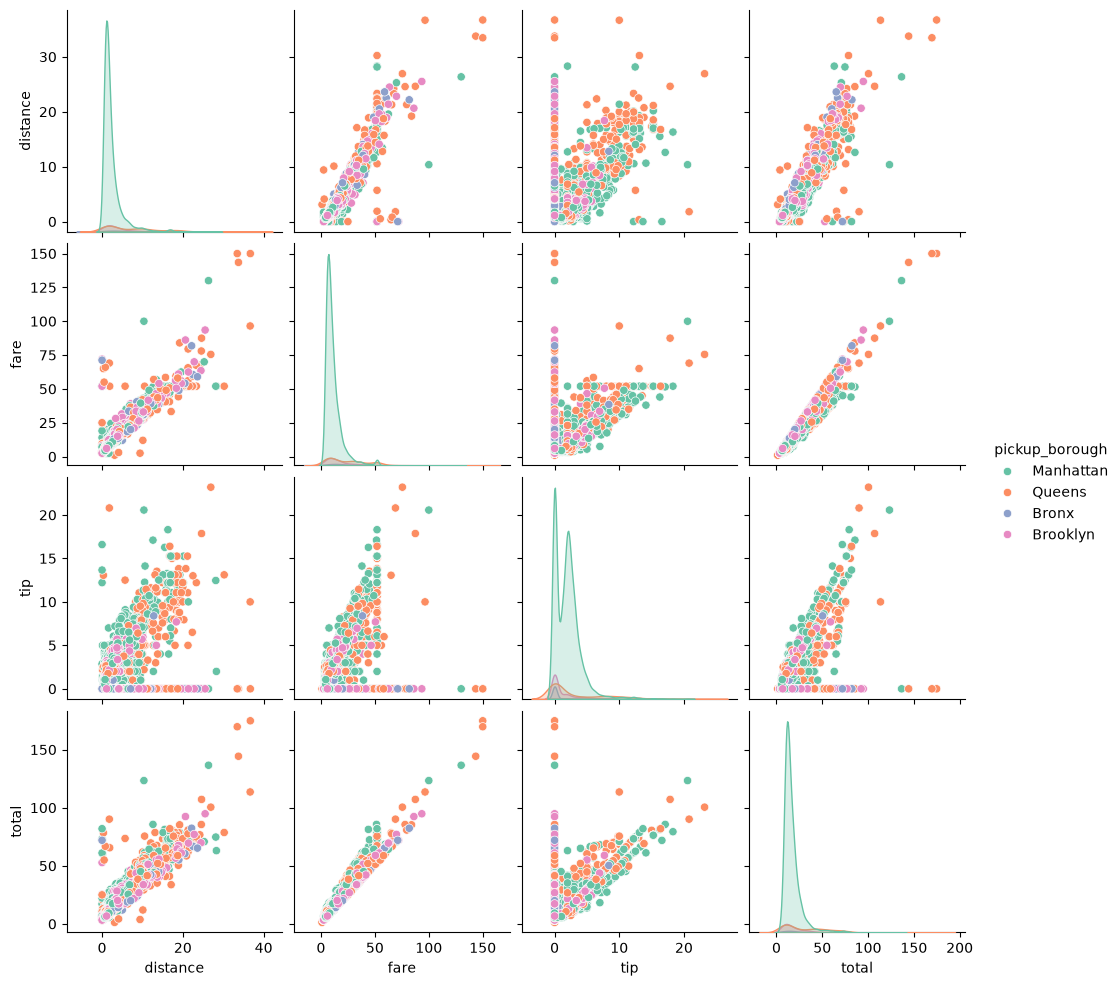

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.pairplot(df, vars=['distance','fare', 'tip','total'], hue='pickup_borough', palette='Set2')
plt.show()

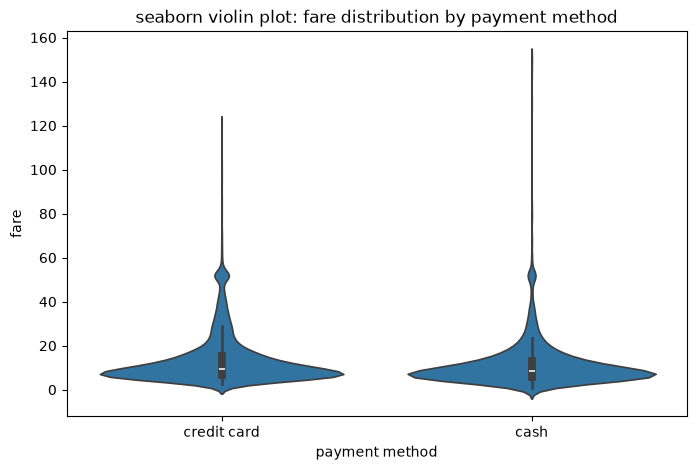

In [12]:
import seaborn as sns 
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='payment', y='fare')
plt.title('seaborn violin plot: fare distribution by payment method')
plt.xlabel('payment method')
plt.ylabel('fare')
plt.show()